In [ ]:
!gdown --fuzzy https://drive.google.com/file/d/1vxFk8ypDTqT1J3PteZIaS2d1ApPvFItz/view?usp=sharing
!unzip Merged_Split.zip
!rm -rf Merged_Split.zip

Streaming output truncated to the last 5000 lines.
  inflating: Merged_Split/train/cardboard/cardboard283.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1866.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_521.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_60.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_44.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1210.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_2200.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_100.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_243.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_729.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1675.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1014.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1207.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1759.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1168.jpg  
  inflating: M

In [ ]:
!pip install ai-edge-model-explorer
!pip install -q tensorflow-model-optimization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.7/84.7 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 69.6 MB/s eta 0:00:00


Found 14468 images belonging to 6 classes.

Showing augmented images for class: cardboard

cardboard - Color Adjustments Pipeline:


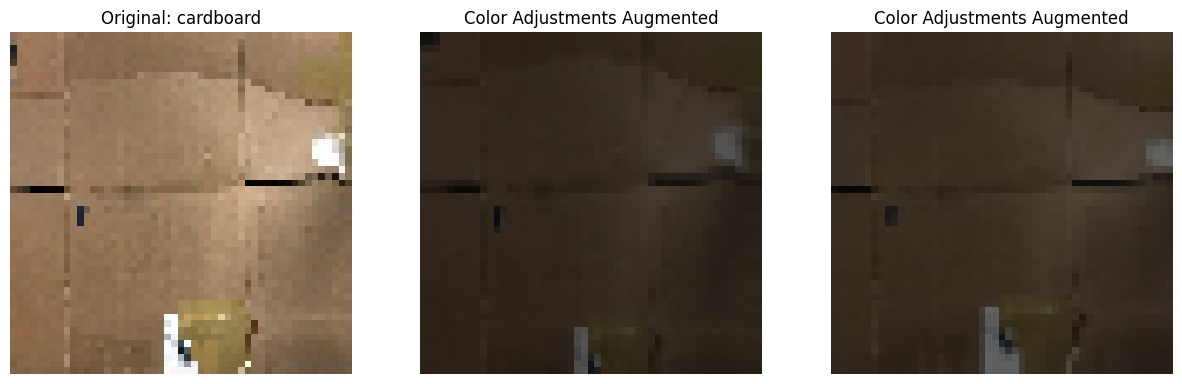


cardboard - Shifting, Rotation, Flips Pipeline:


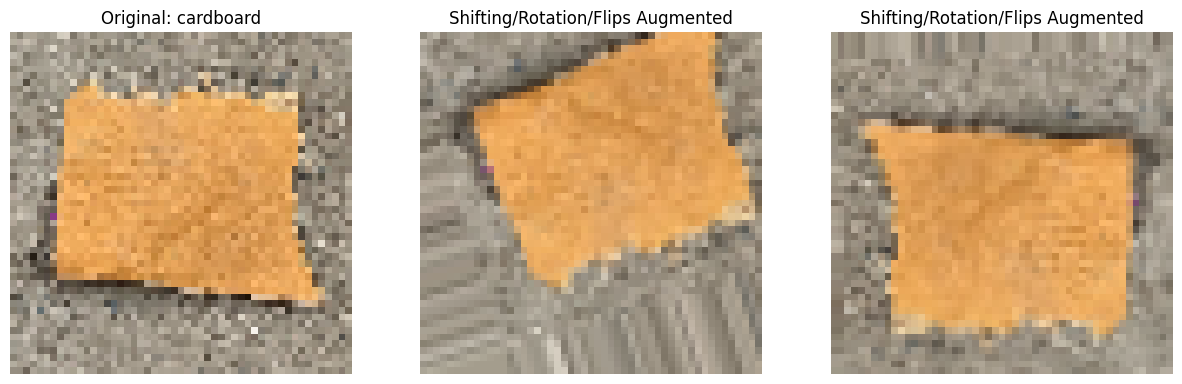


cardboard - Contrast, Zoom, Flip Pipeline:


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1263: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1273: UserWarning: This ImageDataGenerator specifies `featurewise_std_normalization`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(


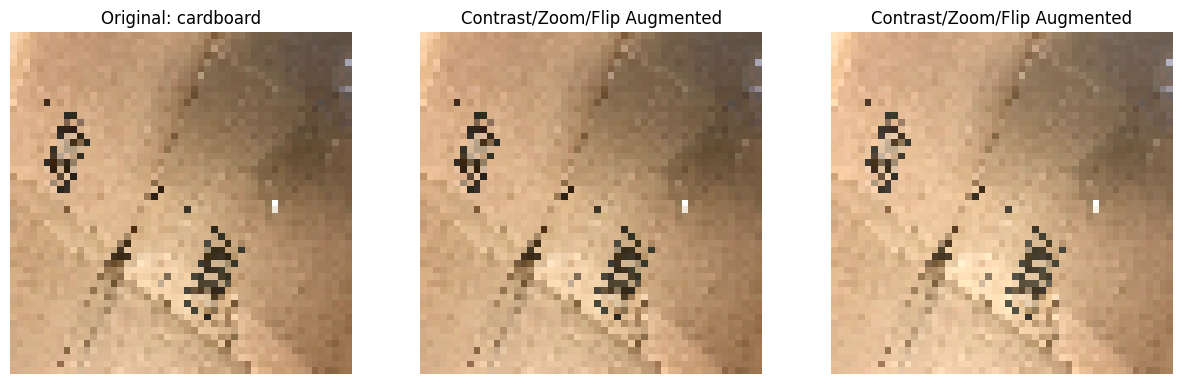


Showing augmented images for class: glass

glass - Color Adjustments Pipeline:


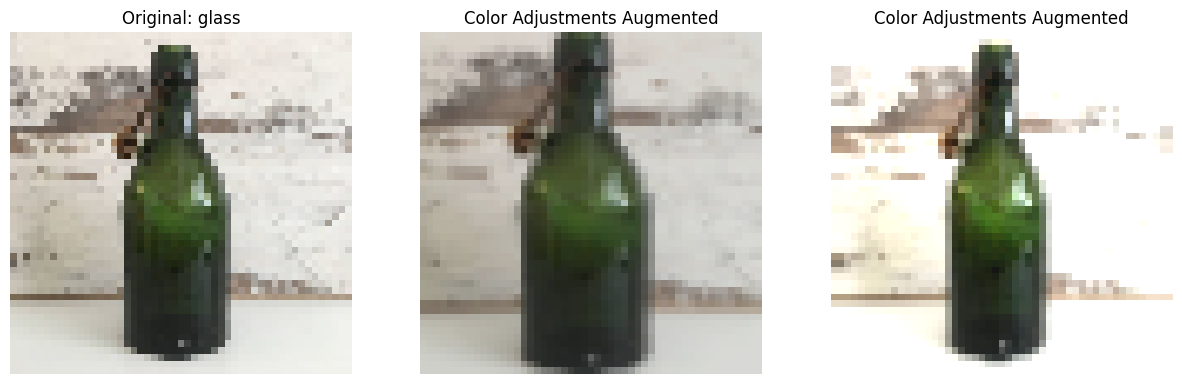


glass - Shifting, Rotation, Flips Pipeline:


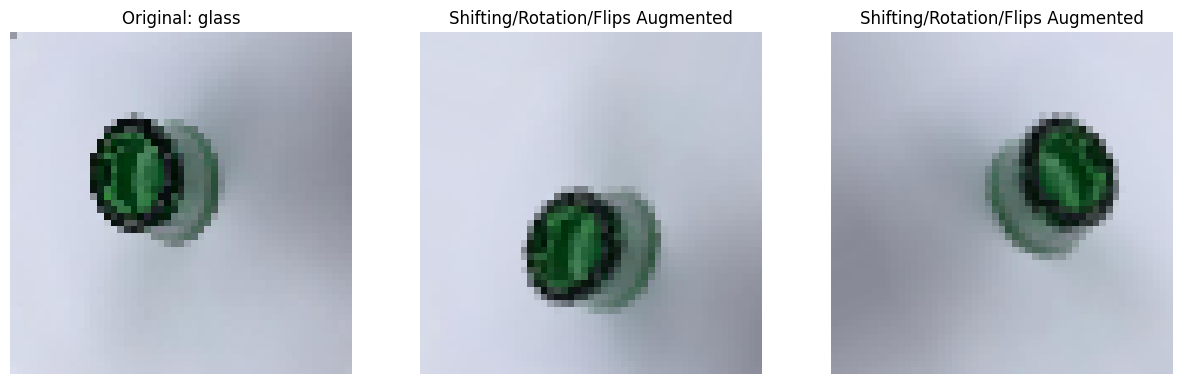


glass - Contrast, Zoom, Flip Pipeline:


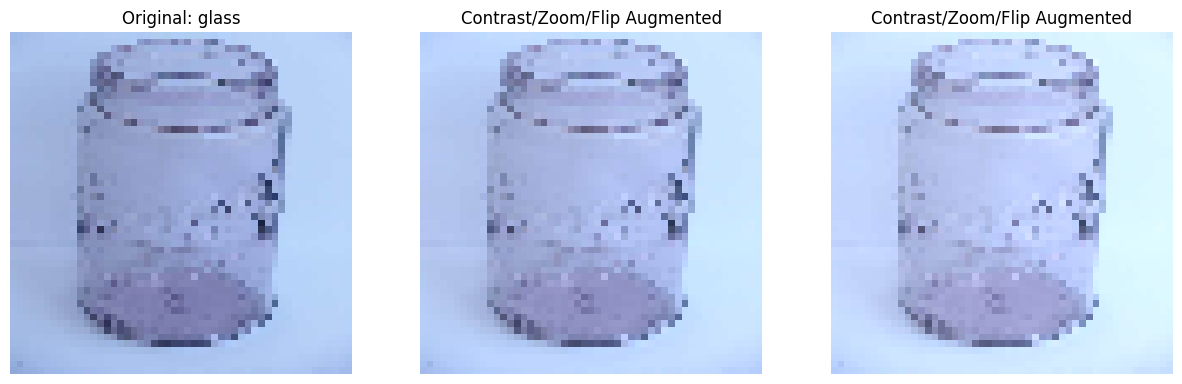


Showing augmented images for class: metal

metal - Color Adjustments Pipeline:


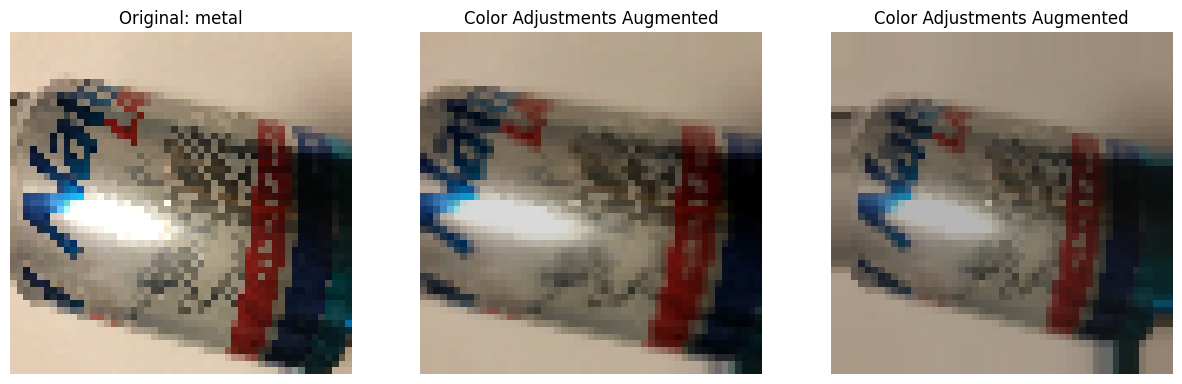


metal - Shifting, Rotation, Flips Pipeline:


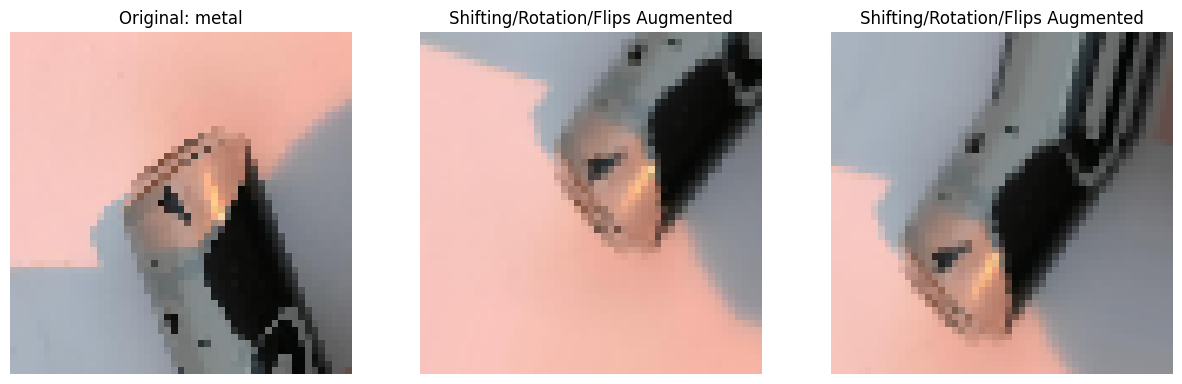


metal - Contrast, Zoom, Flip Pipeline:


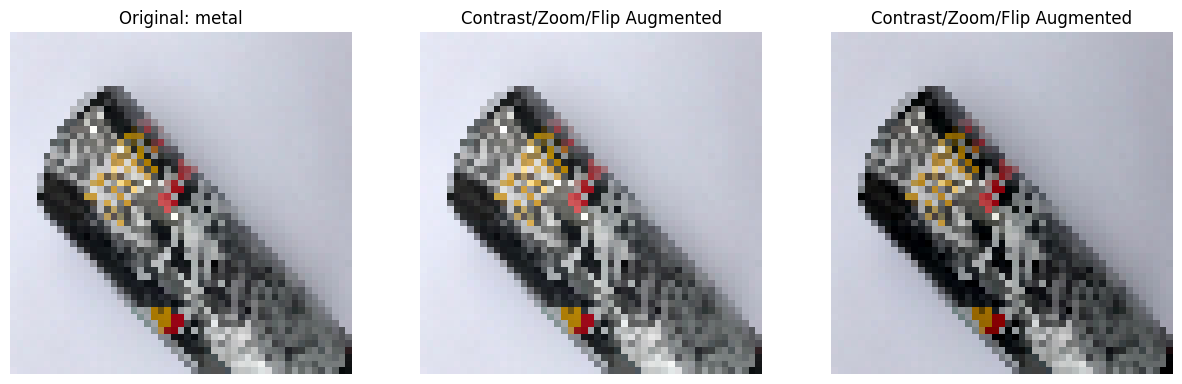


Showing augmented images for class: paper

paper - Color Adjustments Pipeline:


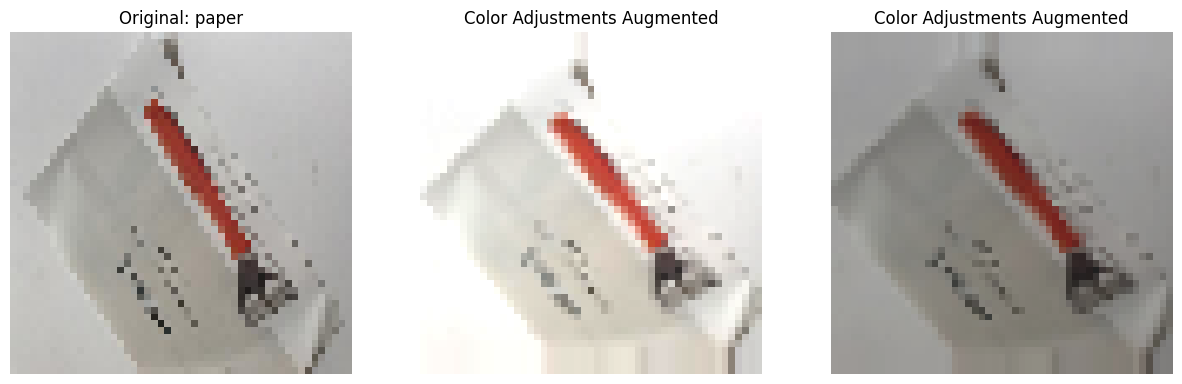


paper - Shifting, Rotation, Flips Pipeline:


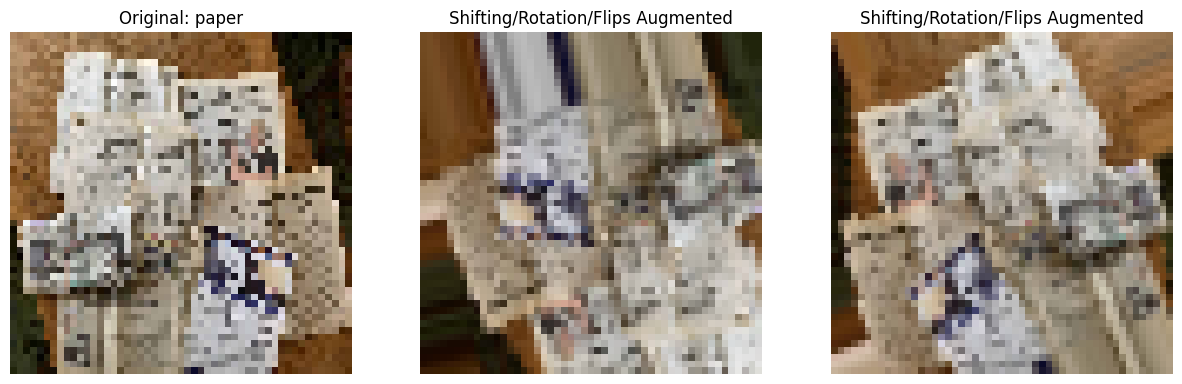


paper - Contrast, Zoom, Flip Pipeline:


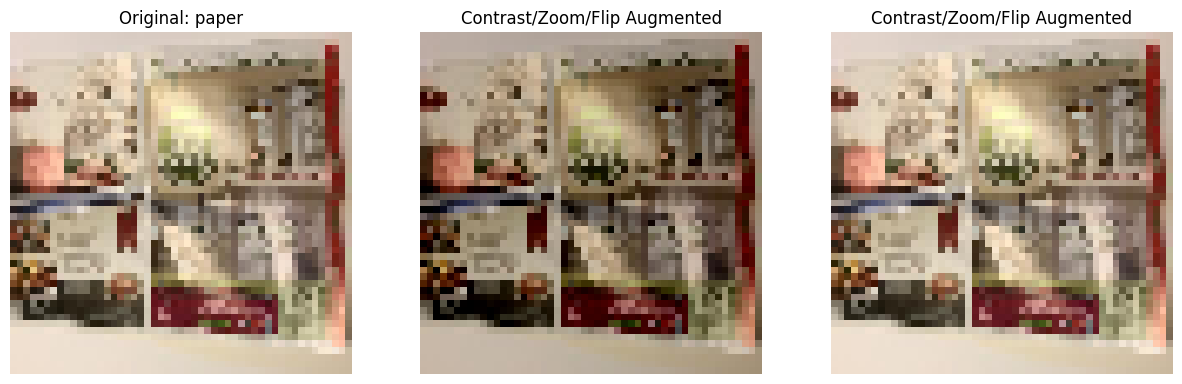


Showing augmented images for class: plastic

plastic - Color Adjustments Pipeline:


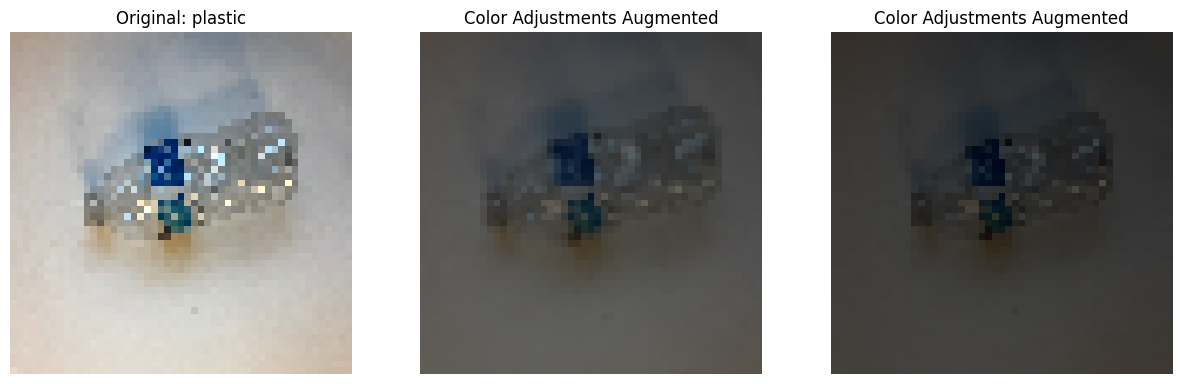


plastic - Shifting, Rotation, Flips Pipeline:


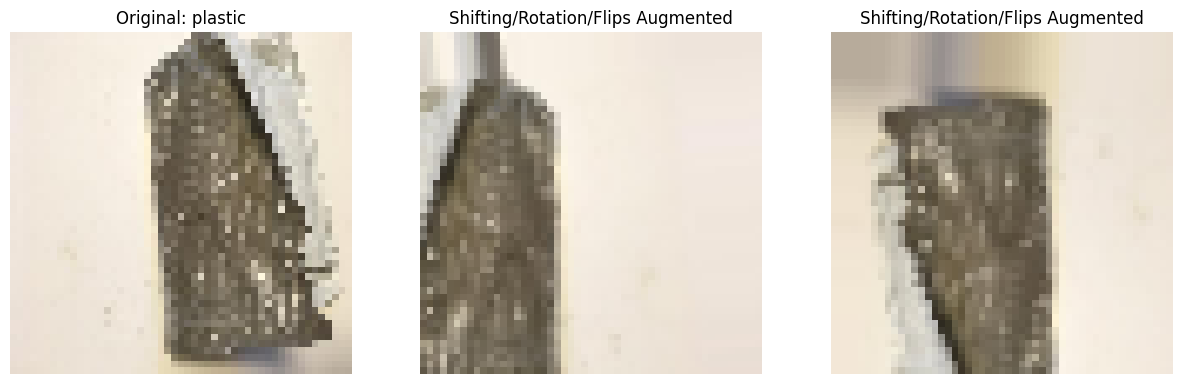


plastic - Contrast, Zoom, Flip Pipeline:


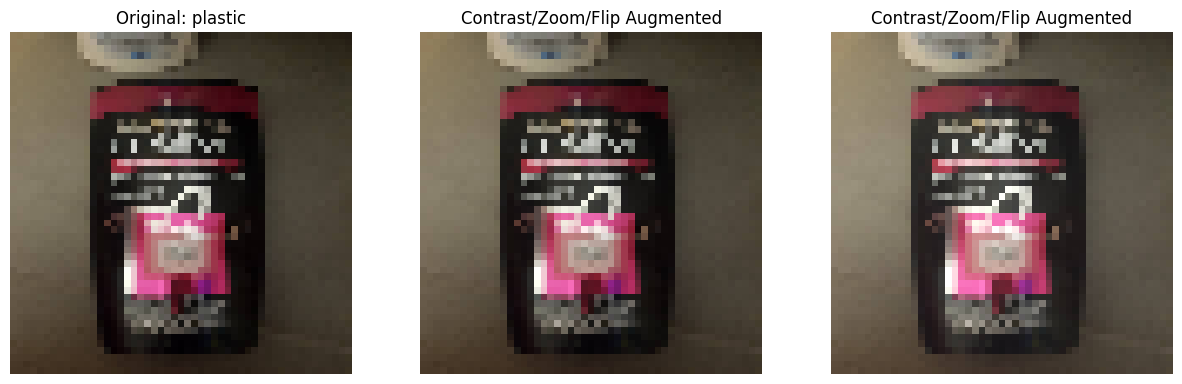


Showing augmented images for class: trash

trash - Color Adjustments Pipeline:


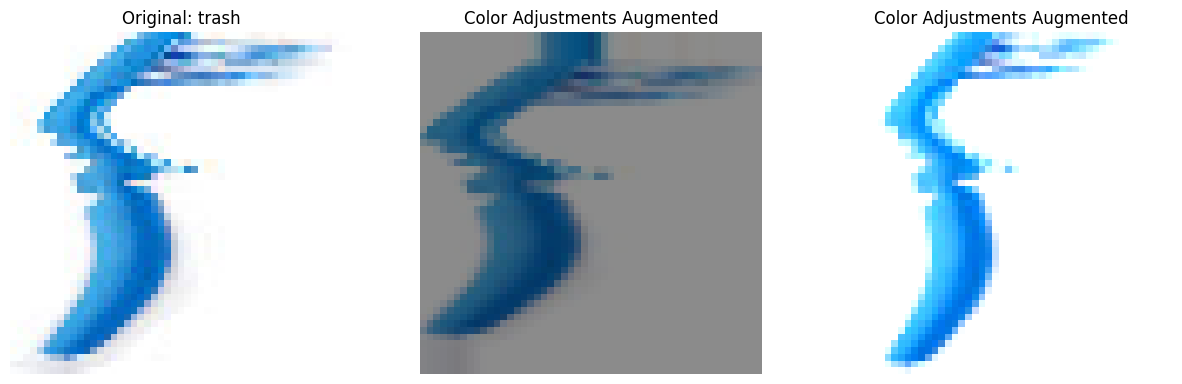


trash - Shifting, Rotation, Flips Pipeline:


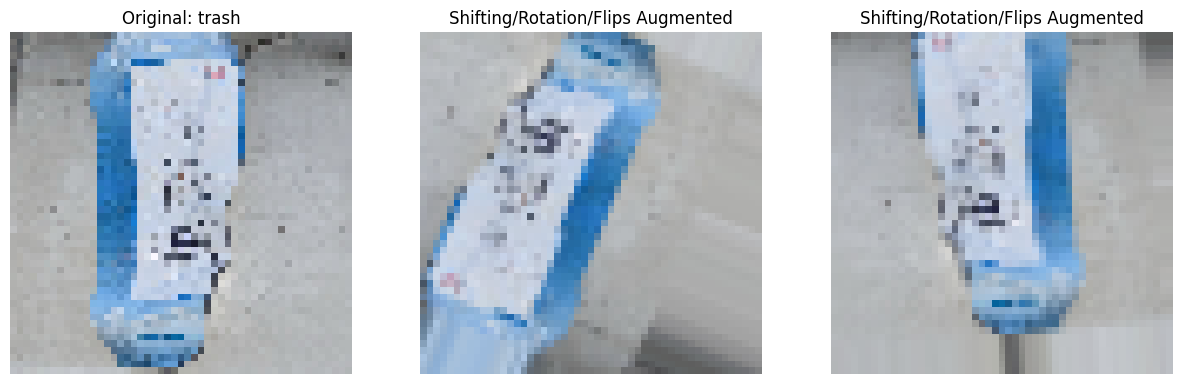


trash - Contrast, Zoom, Flip Pipeline:


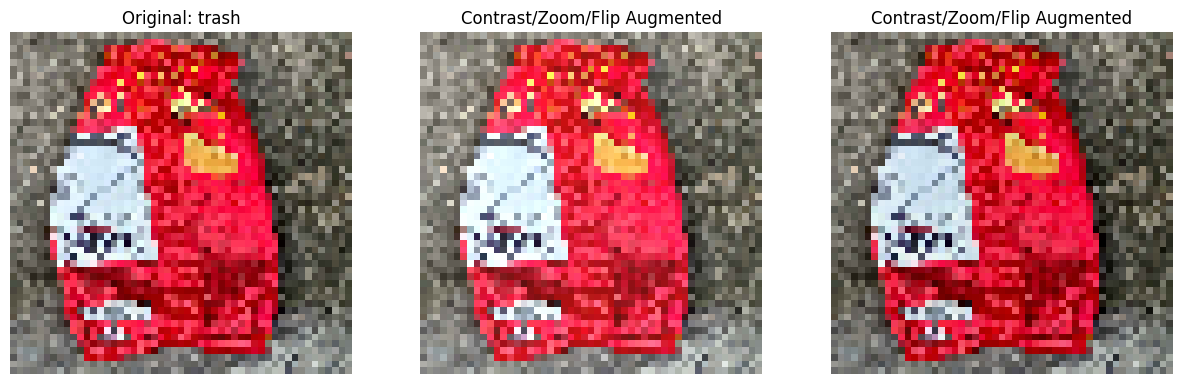

In [ ]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import random
import glob
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# Directory where the dataset is stored
output_dir = '/content/Merged_Split'  # Where to save the split dataset

# Set image dimensions
BATCH_SIZE = 16
IMG_DIM = 51
NUM_CLASSES = 6

# Color adjustment augmentation pipeline
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    brightness_range=[0.3, 1.5],  # Random brightness adjustment
    zoom_range=0.2,               # Random zoom
    channel_shift_range=20.0      # Random channel shift
)

# Shifting, rotation, flips augmentation pipeline
shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    rotation_range=30,   # Random rotation
    width_shift_range=0.2,  # Random horizontal shift
    height_shift_range=0.2,  # Random vertical shift
    shear_range=0.2,     # Shear transformation
    horizontal_flip=True,  # Random horizontal flip
    vertical_flip=True     # Random vertical flip
)

# Contrast, Zoom, Flip augmentation pipeline (Removed ZCA Whitening)
contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    featurewise_center=True,  # Normalize image to have zero mean
    featurewise_std_normalization=True,  # Normalize by the standard deviation
    channel_shift_range=40.0,  # Randomly shift colors of the channels
    cval=0.0  # Value to fill in for pixels outside the boundaries during transformations
)

# Load the dataset and get class indices
train_generator = color_augmentation.flow_from_directory(
    f"{output_dir}/train",
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

class_indices = train_generator.class_indices  # Get class-to-index mapping

# Function to visualize original vs augmented images
def plot_augmented_images(datagen, class_name, class_path, augmentation_type):
    img_paths = glob.glob(f"{class_path}/*.*")  # Match all image types
    if not img_paths:
        print(f"Warning: No images found in {class_path}")
        return

    random_image_path = random.choice(img_paths)
    img = keras.preprocessing.image.load_img(random_image_path, target_size=(IMG_DIM, IMG_DIM))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Display the original image
    axes[0].imshow(img)
    axes[0].set_title(f"Original: {class_name}")
    axes[0].axis("off")

    # Generate and display augmented images
    i = 1
    for batch in datagen.flow(img_array, batch_size=1):
        axes[i].imshow(batch[0])
        axes[i].set_title(f"{augmentation_type} Augmented")
        axes[i].axis("off")
        i += 1
        if i == 3:
            break
    plt.show()

# Loop over each class and display original vs augmented images
for class_name in sorted(class_indices.keys()):
    print(f"\nShowing augmented images for class: {class_name}")

    # Display images for color adjustment pipeline
    print(f"\n{class_name} - Color Adjustments Pipeline:")
    plot_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}", "Color Adjustments")

    # Display images for shifting, rotation, flips pipeline
    print(f"\n{class_name} - Shifting, Rotation, Flips Pipeline:")
    plot_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Shifting/Rotation/Flips")

    # Display images for contrast, zoom, flip pipeline
    print(f"\n{class_name} - Contrast, Zoom, Flip Pipeline:")
    plot_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Contrast/Zoom/Flip")

In [ ]:
import os
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tqdm.notebook import tqdm  # For progress bar
import glob

# Directory where the augmented images will be saved
augmented_dir = '/content/augmented_train_images'  # Update to your preferred directory
os.makedirs(augmented_dir, exist_ok=True)

# Augmentation pipelines (already defined in previous code)
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    brightness_range=[0.3, 1.5],
    zoom_range=0.2,
    channel_shift_range=20.0
)

shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    vertical_flip=True
)

contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    featurewise_center=True,
    featurewise_std_normalization=True,
    zca_whitening=True,
    zca_epsilon=1e-06,
    channel_shift_range=40.0,
    cval=0.0,
    interpolation_order=6
)

# Function to save augmented images for a given pipeline
def save_augmented_images(datagen, class_name, class_path):
    # Create a directory to save the augmented images for each class
    class_augmented_dir = os.path.join(augmented_dir, class_name)
    os.makedirs(class_augmented_dir, exist_ok=True)

    # Get all images in the class folder
    img_paths = glob.glob(f"{class_path}/*.jpg")

    # Loop through images and apply augmentation
    for i, img_path in enumerate(tqdm(img_paths, desc=f"Saving augmented images for {class_name}", unit="image")):
        img = keras.preprocessing.image.load_img(img_path, target_size=(IMG_DIM, IMG_DIM))
        img_array = keras.preprocessing.image.img_to_array(img)
        img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

        # Apply the augmentation and save images
        for batch in datagen.flow(img_array, batch_size=1, save_to_dir=class_augmented_dir, save_prefix=f"{class_name}_aug", save_format="jpeg"):
            break  # Save one augmented image per original image

# Apply and save augmented images for each class using the three augmentation pipelines
for class_name in sorted(class_indices.keys()):
    print(f"\nProcessing class: {class_name}")

    # Save images for color adjustment pipeline
    save_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for shifting, rotation, flips pipeline
    save_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for contrast, zoom, flip pipeline
    save_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

print("\nAugmented images saved successfully!")


Processing class: cardboard


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1054: UserWarning: This ImageDataGenerator specifies `zca_whitening` which overrides setting of`featurewise_std_normalization`.
  warnings.warn(


Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

...


Processing class: trash


Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]


Augmented images saved successfully!


In [ ]:
augmented_train_dir = '/content/augmented_train_images'  # Adjust this path if your augmented train images are stored elsewhere
val_dir = '/content/Merged_Split/val'  # Your validation directory path

# Create the ImageDataGenerator for the augmented images
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # You can add other augmentations here if needed
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Validation set only has rescaling (no augmentation)
)

# Load the augmented training and validation data
train_dataset_tf = train_datagen.flow_from_directory(
    augmented_train_dir,  # Path to the augmented training images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=True  # Shuffle training data
)

val_dataset_tf = val_datagen.flow_from_directory(
    val_dir,  # Path to the validation images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False # No shuffle for validation data
)
# Assuming you have a test directory similar to train and val
test_dir = '/content/Merged_Split/test'  # Adjust this path to your test directory

# Create ImageDataGenerator for test data
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Only rescaling for test data
)

# Load the test dataset
test_dataset_tf = test_datagen.flow_from_directory(
    test_dir,  # Path to the test images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for test data
)

Found 29565 images belonging to 6 classes.
Found 1810 images belonging to 6 classes.
Found 1812 images belonging to 6 classes.


In [ ]:
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

# Set random seed
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

IMG_DIM = 51
NUM_CLASSES = 6

# Define GSConv (based on Fig. 2)
class GSConv(tf.keras.layers.Layer):
    def __init__(self, out_channels):
        super(GSConv, self).__init__()
        self.conv1 = layers.Conv2D(out_channels // 2, kernel_size=1, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(out_channels // 2, kernel_size=3, padding='same', activation='relu')
        self.shuffle = layers.Lambda(lambda x: tf.experimental.numpy.moveaxis(x, 1, -1))  # simple channel shuffle

    def call(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x)
        out = tf.concat([x1, x2], axis=-1)
        return self.shuffle(out)

# Define GRSCPSELAN (approximated residual conv block)
class GRSCPSELAN(tf.keras.layers.Layer):
    def __init__(self, filters):
        super(GRSCPSELAN, self).__init__()
        self.conv1 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.shortcut = layers.Conv2D(filters, 1, padding='same')
        self.bn = layers.BatchNormalization()
        self.relu = layers.ReLU()

    def call(self, x, training=False):
        residual = self.shortcut(x)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.bn(x + residual, training=training)
        return self.relu(x)

# Build LWCNet-Inspired Classification Model
def build_LWCNet(input_shape=(IMG_DIM, IMG_DIM, 3), num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=input_shape)

    # Backbone
    x = layers.Conv2D(32, 3, strides=1, padding='same', activation='relu')(inputs)
    x = GRSCPSELAN(64)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(128)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(256)(x)

    # Neck
    x = GSConv(256)(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Head (classification)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

# Instantiate and compile the model
tf_model = build_LWCNet()
tf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
tf_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 51, 51, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 51, 51, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ grscpselan_6 (GRSCPSELAN)       │ (None, 51, 51, 64)     │        57,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ grscpselan_7 (GRSCPSELAN)       │ (None, 25, 25, 128)    │       230,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ grscpselan_8 (GRSCPSELAN)       │ (None, 12, 12, 256)    │       919,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gs_conv_2 (GSConv)              │ (None, 12, 256, 12)    │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 12)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,539,302 (5.87 MB)

 Trainable params: 1,538,406 (5.87 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import csv
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, Callback
from sklearn.metrics import f1_score
from tqdm.keras import TqdmCallback
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ==================== Custom F1 Score Callback ====================
class F1ScoreCallback(Callback):
    def __init__(self, validation_data, log_history):
        super().__init__()
        self.validation_data = validation_data
        self.log_history = log_history

    def on_epoch_end(self, epoch, logs=None):
        val_images, val_labels = self.validation_data
        val_predict = np.argmax(self.model.predict(val_images), axis=1)
        val_true = np.argmax(val_labels, axis=1)
        val_f1 = f1_score(val_true, val_predict, average='weighted')

        logs['val_f1_score'] = val_f1

        # Print the metrics for the current epoch
        print(f"Epoch {epoch + 1}/{self.params['epochs']} - "
              f"accuracy: {logs.get('accuracy', 'N/A'):.4f} - "
              f"loss: {logs.get('loss', 'N/A'):.4f} - "
              f"val_accuracy: {logs.get('val_accuracy', 'N/A'):.4f} - "
              f"val_loss: {logs.get('val_loss', 'N/A'):.4f} - "
              f"val_f1_score: {val_f1:.4f}")

        # Save the metrics to the log_history list
        self.log_history.append({
            'epoch': epoch + 1,
            'accuracy': logs.get('accuracy', 'N/A'),
            'loss': logs.get('loss', 'N/A'),
            'val_accuracy': logs.get('val_accuracy', 'N/A'),
            'val_loss': logs.get('val_loss', 'N/A'),
            'val_f1_score': val_f1
        })

# ==================== Compile Model ====================
tf_model.compile(
    loss=tf.keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    metrics=['accuracy'],
    run_eagerly=False
)

# ==================== Dataset Setup ====================
# Adjust these depending on your dataset setup
steps_per_epoch_train = np.ceil(train_dataset_tf.samples / BATCH_SIZE).astype(int)
steps_per_epoch_val = np.ceil(val_dataset_tf.samples / BATCH_SIZE).astype(int)

# ==================== Preload Validation Data for F1 Score ====================
val_X, val_y = [], []
for _ in range(steps_per_epoch_val):
    batch_X, batch_y = next(val_dataset_tf)
    val_X.append(batch_X)
    val_y.append(batch_y)
val_X = np.vstack(val_X)
val_y = np.vstack(val_y)

# ==================== Callbacks ====================
checkpoint = ModelCheckpoint(
    filepath='/content/drive/MyDrive/paper4/best_model.h5',
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Initialize the list to store logs
log_history = []

f1_callback = F1ScoreCallback(validation_data=(val_X, val_y), log_history=log_history)

# ==================== TQDM Callback (Modified) ====================
class CustomTqdmCallback(TqdmCallback):
    def on_epoch_end(self, epoch, logs=None):
        # This callback does not update the progress bar, only prints epoch metrics
        pass

# ==================== Training ====================
EPOCHS = 50
history = tf_model.fit(
    train_dataset_tf,
    steps_per_epoch=steps_per_epoch_train,
    validation_data=val_dataset_tf,
    validation_steps=steps_per_epoch_val,
    epochs=EPOCHS,
    callbacks=[
        CustomTqdmCallback(),
        checkpoint,
        early_stopping,
        f1_callback
    ],
    verbose=0  # Use Tqdm for progress instead of Keras bar
)

# ==================== Save Model ====================
tf_model.save('/content/saved_model.h5')
print("\nModel training complete and saved to /content/saved_model.h5")

# ==================== Save Metrics to CSV ====================
csv_path = '/content/drive/MyDrive/paper4/training_metrics.csv'
with open(csv_path, mode='w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=[
        'epoch', 'accuracy', 'loss', 'val_accuracy', 'val_loss', 'val_f1_score'
    ])
    writer.writeheader()  # Write the header row
    for row in log_history:
        writer.writerow(row)

print(f"\nMetrics saved to {csv_path}")




0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]


Epoch 1: val_accuracy improved from -inf to 0.31326, saving model to /content/drive/MyDrive/paper4/best_model.h5


57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
Epoch 1/50 - accuracy: 0.2498 - loss: 1.7279 - val_accuracy: 0.3133 - val_loss: 1.6250 - val_f1_score: 0.2550

Epoch 2: val_accuracy improved from 0.31326 to 0.39448, saving model to /content/drive/MyDrive/paper4/best_model.h5


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Epoch 2/50 - accuracy: 0.3474 - loss: 1.6019 - val_accuracy: 0.3945 - val_loss: 1.5302 - val_f1_score: 0.3284

Epoch 3: val_accuracy improved from 0.39448 to 0.48729, saving model to /content/drive/MyDrive/paper4/best_model.h5


...

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Epoch 20/50 - accuracy: 0.7961 - loss: 0.6072 - val_accuracy: 0.8243 - val_loss: 0.6171 - val_f1_score: 0.8234

Epoch 21: val_accuracy did not improve from 0.82431
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 21/50 - accuracy: 0.8066 - loss: 0.5751 - val_accuracy: 0.8133 - val_loss: 0.6832 - val_f1_score: 0.8121

Epoch 22: val_accuracy did not improve from 0.82431
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 22/50 - accuracy: 0.8199 - loss: 0.5431 - val_accuracy: 0.8171 - val_loss: 0.6625 - val_f1_score: 0.8152

Epoch 23: val_accuracy improved from 0.82431 to 0.83536, saving model to /content/drive/MyDrive/paper4/best_model.h5


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Epoch 23/50 - accuracy: 0.8355 - loss: 0.5001 - val_accuracy: 0.8354 - val_loss: 0.6001 - val_f1_score: 0.8348

Epoch 24: val_accuracy did not improve from 0.83536
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Epoch 24/50 - accuracy: 0.8418 - loss: 0.4835 - val_accuracy: 0.8072 - val_loss: 0.6385 - val_f1_score: 0.8090

Epoch 25: val_accuracy did not improve from 0.83536
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 25/50 - accuracy: 0.8539 - loss: 0.4560 - val_accuracy: 0.7912 - val_loss: 0.7269 - val_f1_score: 0.7897

Epoch 26: val_accuracy improved from 0.83536 to 0.84309, saving model to /content/drive/MyDrive/paper4/best_model.h5


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Epoch 26/50 - accuracy: 0.8656 - loss: 0.4203 - val_accuracy: 0.8431 - val_loss: 0.6478 - val_f1_score: 0.8413

Epoch 27: val_accuracy did not improve from 0.84309
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 27/50 - accuracy: 0.8721 - loss: 0.3961 - val_accuracy: 0.7906 - val_loss: 0.7648 - val_f1_score: 0.7938

Epoch 28: val_accuracy did not improve from 0.84309
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 28/50 - accuracy: 0.8792 - loss: 0.3803 - val_accuracy: 0.7238 - val_loss: 1.0914 - val_f1_score: 0.7293

Epoch 29: val_accuracy did not improve from 0.84309
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Epoch 29/50 - accuracy: 0.8889 - loss: 0.3576 - val_accuracy: 0.8077 - val_loss: 0.7638 - val_f1_score: 0.8073

Epoch 30: val_accuracy did not improve from 0.84309
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Epoch 30/50 - accuracy: 0.8998 - loss: 0.3234 - val_accuracy: 0.8304 - val_loss: 0.6974 - val_f1_score: 0.8311

Epoch 31: val_accuracy did not i


Model training complete and saved to /content/saved_model.h5

Metrics saved to /content/drive/MyDrive/paper4/training_metrics.csv
109/114 ━━━━━━━━━━━━━━━━━━━━ 1s 211ms/step

InternalError: Graph execution error:

Detected at node StatefulPartitionedCall defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.11/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.11/dist-packages/traitlets/config/application.py", line 992, in launch_instance

  File "/usr/local/lib/python3.11/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.11/dist-packages/tornado/platform/asyncio.py", line 205, in start

  File "/usr/lib/python3.11/asyncio/base_events.py", line 608, in run_forever

  File "/usr/lib/python3.11/asyncio/base_events.py", line 1936, in _run_once

  File "/usr/lib/python3.11/asyncio/events.py", line 84, in _run

  File "/usr/local/lib/python3.11/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File "/usr/local/lib/python3.11/dist-packages/ipy

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


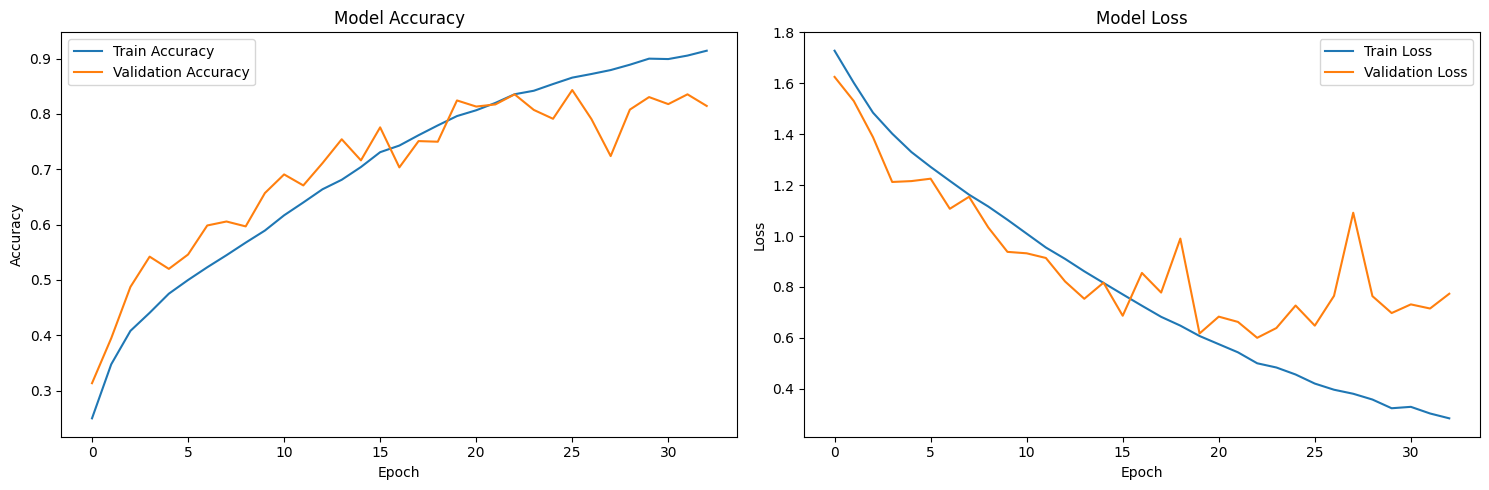

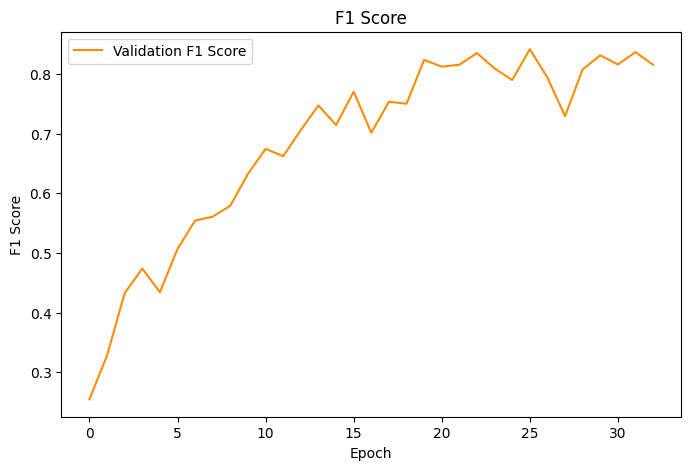

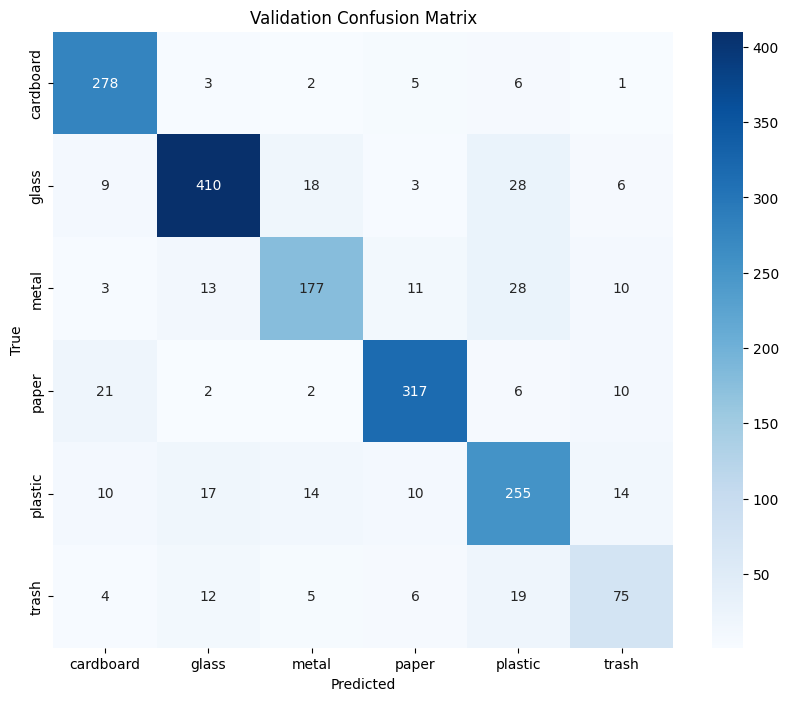

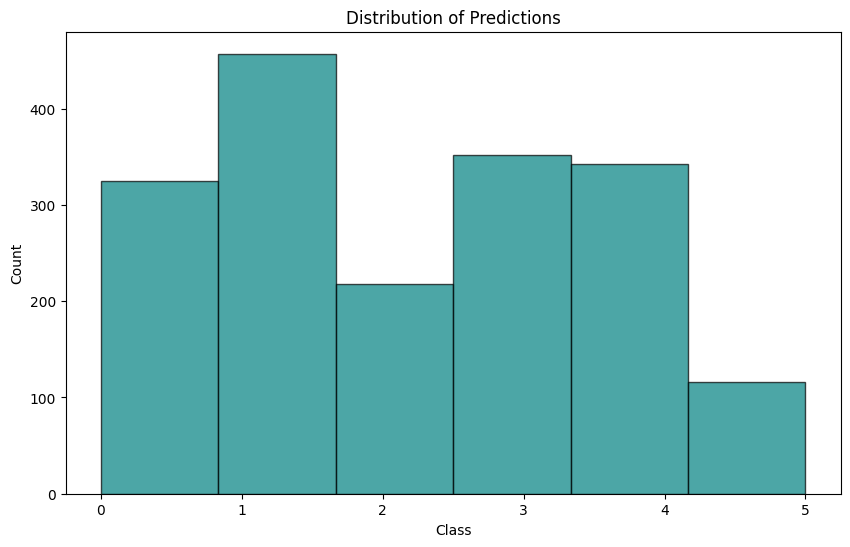

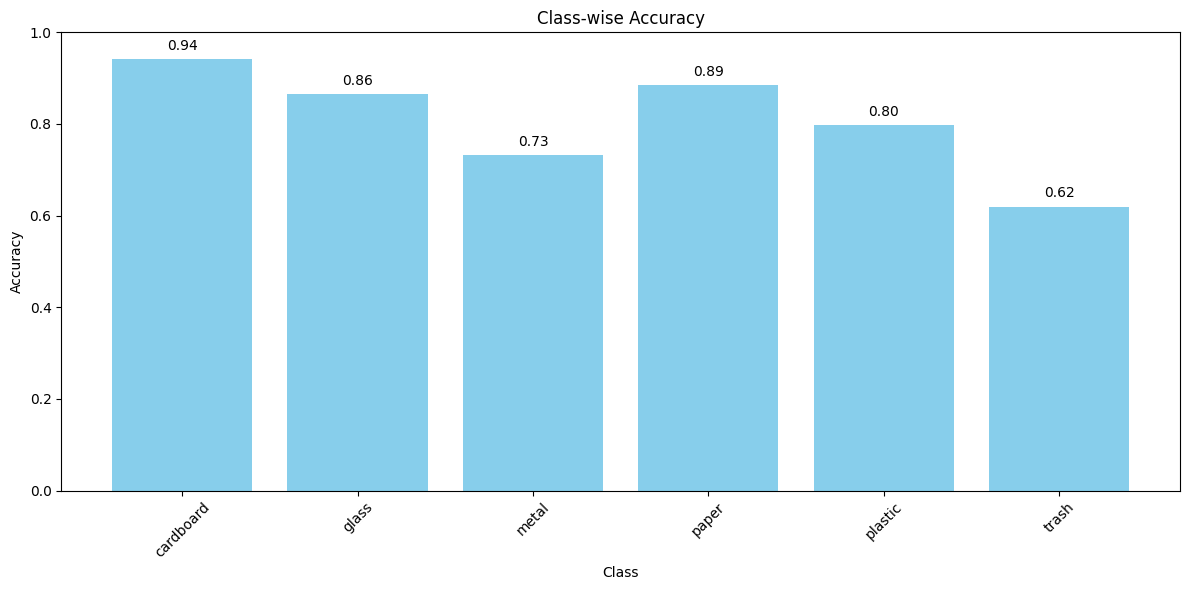

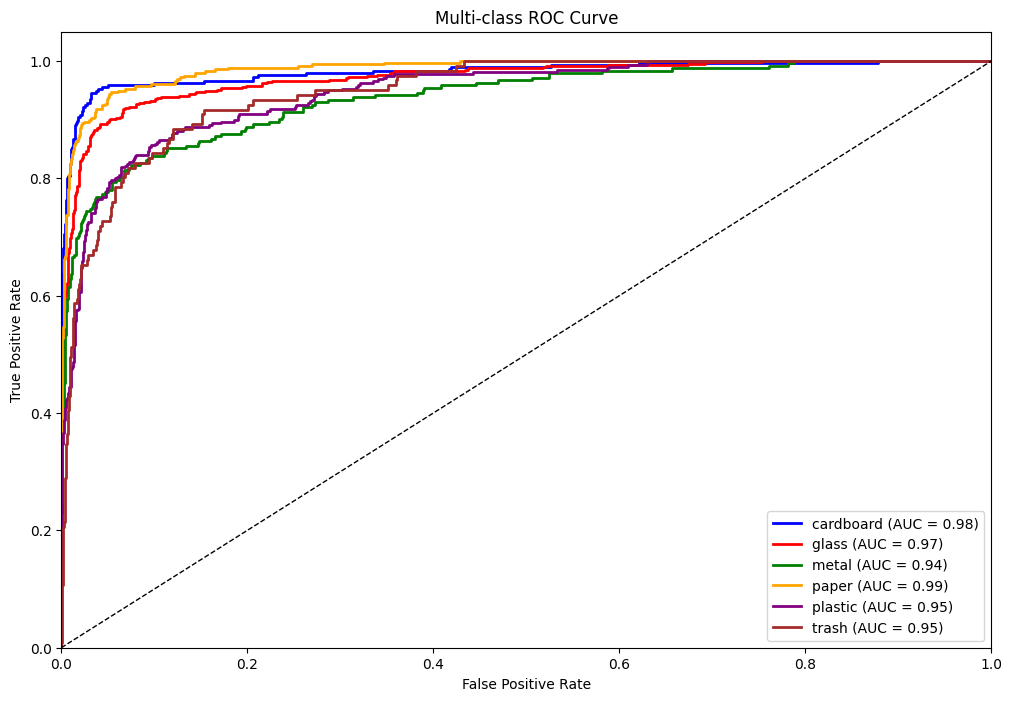

Created model performance dashboard at /content/model_performance_dashboard.png
✅ All visualizations complete and saved!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc, f1_score
from itertools import cycle
from PIL import Image
import os

# =================== Prepare Predictions ===================
val_preds = tf_model.predict(val_X)
val_pred_classes = np.argmax(val_preds, axis=1)
true_classes = np.argmax(val_y, axis=1)
true_labels = val_y  # For ROC

# =================== 1. Training History Visualization ===================
plt.figure(figsize=(15, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('/content/training_history.png')
plt.show()

# =================== 2. F1 Score Visualization ===================
if 'val_f1_score' in history.history and history.history['val_f1_score']:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['val_f1_score'], label='Validation F1 Score', color='darkorange')
    plt.title('F1 Score')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.savefig('/content/f1_score_history.png')
    plt.show()

# =================== 3. Confusion Matrix ===================
try:
    class_names = list(val_dataset_tf.class_indices.keys())
except AttributeError:
    class_names = [f'Class {i}' for i in range(len(np.unique(true_classes)))]

plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_classes, val_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.savefig('/content/confusion_matrix.png')
plt.show()

# =================== 4. Prediction Distribution ===================
plt.figure(figsize=(10, 6))
plt.hist(val_pred_classes, bins=len(np.unique(val_pred_classes)), alpha=0.7, color='teal', edgecolor='black')
plt.title('Distribution of Predictions')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(np.unique(val_pred_classes))
plt.savefig('/content/prediction_distribution.png')
plt.show()

# =================== 5. Class-wise Accuracy ===================
class_accuracy = []
for i in range(len(class_names)):
    mask = (true_classes == i)
    correct = np.sum(val_pred_classes[mask] == i)
    total = np.sum(mask)
    class_accuracy.append(correct / total if total > 0 else 0)

plt.figure(figsize=(12, 6))
plt.bar(range(len(class_names)), class_accuracy, color='skyblue')
plt.title('Class-wise Accuracy')
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(range(len(class_names)), class_names, rotation=45)
for i, acc in enumerate(class_accuracy):
    plt.text(i, acc + 0.02, f'{acc:.2f}', ha='center')
plt.tight_layout()
plt.savefig('/content/class_accuracy.png')
plt.show()

# =================== 6. ROC Curve (One-vs-Rest) ===================
plt.figure(figsize=(12, 8))

y_test = true_labels
y_score = val_preds

n_classes = y_test.shape[1]
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown', 'cyan', 'magenta', 'olive', 'darkblue'])

for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc='lower right')
plt.savefig('/content/roc_curve.png')
plt.show()

# =================== 7. Summary Dashboard ===================
image_paths = [
    '/content/training_history.png',
    '/content/confusion_matrix.png',
    '/content/class_accuracy.png',
    '/content/prediction_distribution.png'
]

existing_images = [path for path in image_paths if os.path.exists(path)]
if len(existing_images) >= 2:
    images = [Image.open(img_path) for img_path in existing_images]

    cols = 2
    rows = (len(images) + cols - 1) // cols
    widths, heights = zip(*(img.size for img in images))

    max_width = max(widths)
    max_height = max(heights)
    dashboard = Image.new('RGB', (cols * max_width, rows * max_height), (255, 255, 255))

    for idx, img in enumerate(images):
        x = (idx % cols) * max_width
        y = (idx // cols) * max_height
        dashboard.paste(img, (x, y))

    dashboard.save('/content/model_performance_dashboard.png')
    print("Created model performance dashboard at /content/model_performance_dashboard.png")

print("✅ All visualizations complete and saved!")


❌ Error loading model: Unknown layer: 'GRSCPSELAN'. Please ensure you are using a `keras.utils.custom_object_scope` and that this object is included in the scope. See https://www.tensorflow.org/guide/keras/save_and_serialize#registering_the_custom_object for details.


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


114/114 ━━━━━━━━━━━━━━━━━━━━ 32s 275ms/step

✅ Test Accuracy: 0.8273

Classification Report:
               precision    recall  f1-score   support

   cardboard       0.85      0.91      0.88       295
       glass       0.91      0.84      0.88       474
       metal       0.78      0.77      0.77       242
       paper       0.88      0.87      0.87       359
     plastic       0.74      0.79      0.76       320
       trash       0.65      0.66      0.66       122

    accuracy                           0.83      1812
   macro avg       0.80      0.81      0.80      1812
weighted avg       0.83      0.83      0.83      1812



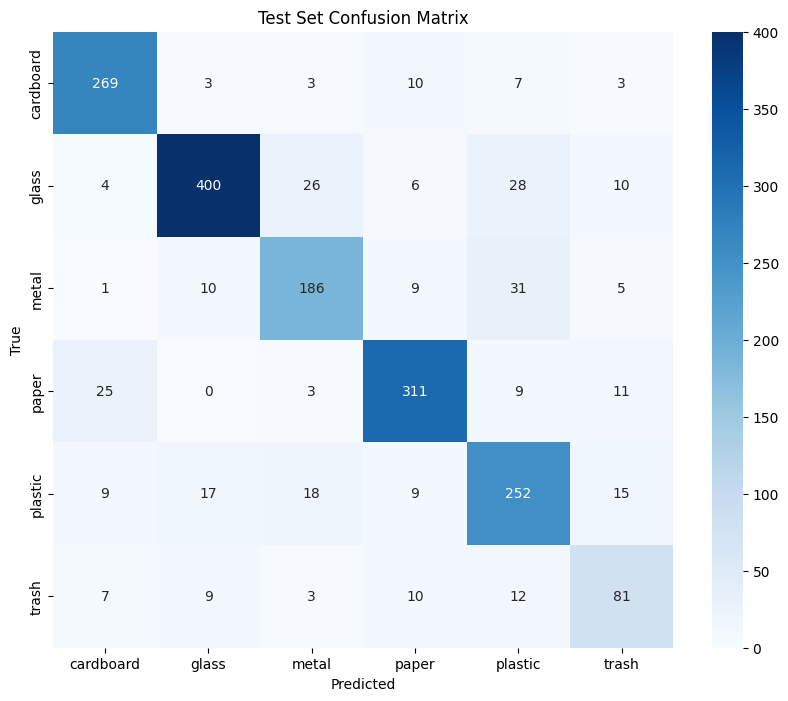

✅ Test F1 Score: 0.8279


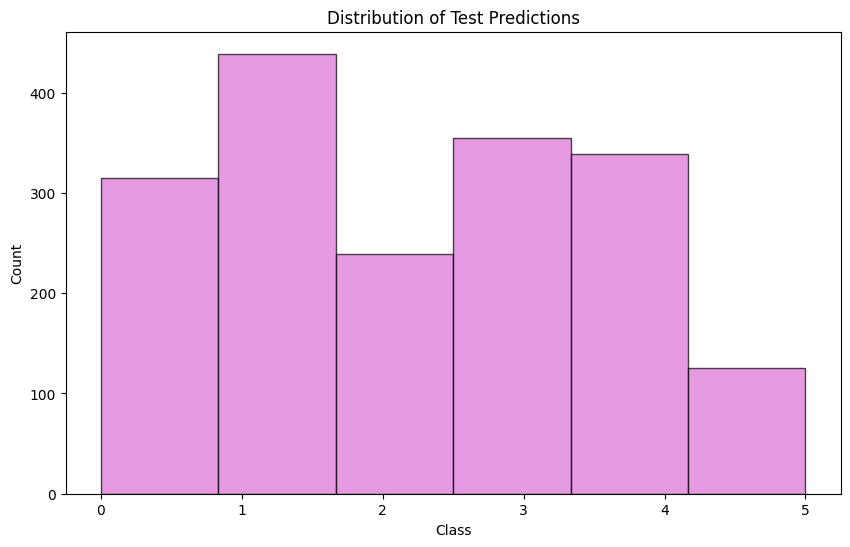

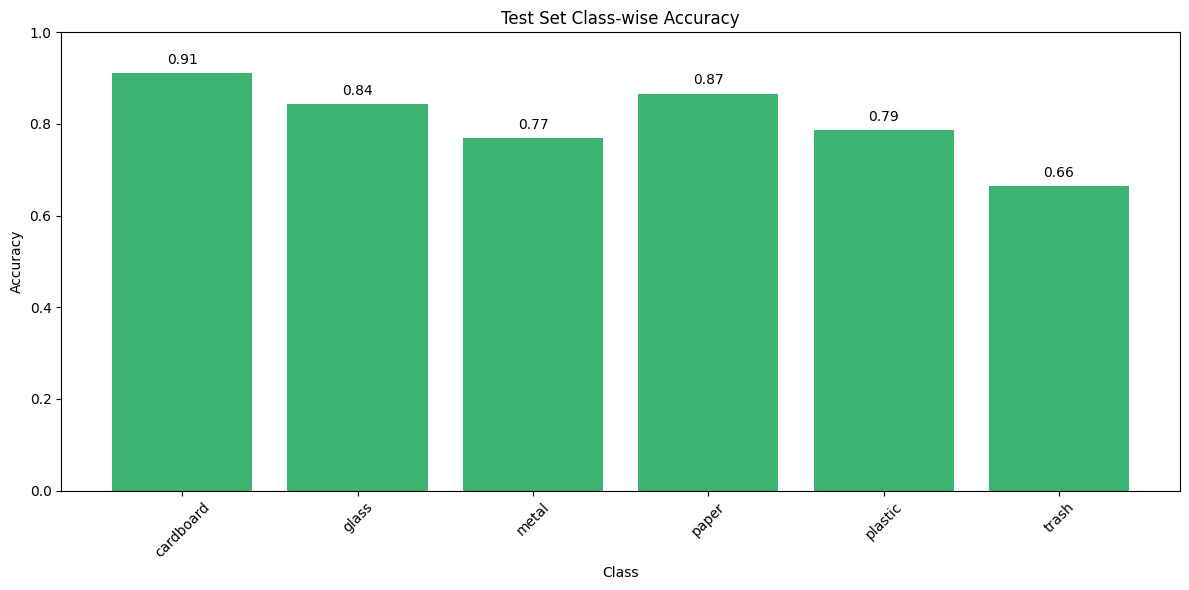

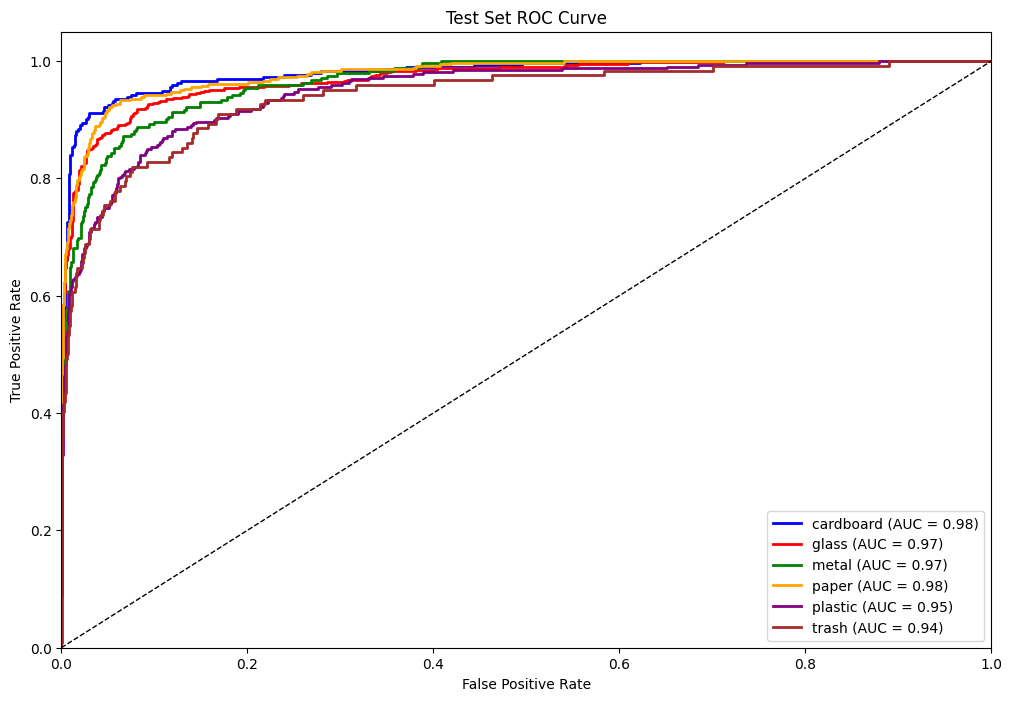

✅ Created test performance dashboard at /content/test_performance_dashboard.png

✅ Testing and visualizations complete!


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_curve, auc
from itertools import cycle
from PIL import Image
import os

# ✅ Load the trained model
model_path = "/content/saved_model.h5"
try:
    tf_model = tf.keras.models.load_model(model_path)
    print(f"✅ Model loaded successfully from {model_path}")
except Exception as e:
    print(f"❌ Error loading model: {e}")

# ✅ Ensure test dataset is properly defined
try:
    steps_per_epoch_test = np.ceil(test_dataset_tf.samples / BATCH_SIZE).astype(int)
except AttributeError:
    raise ValueError("❌ The test dataset is not correctly defined or missing.")

# ✅ Generate test predictions
test_preds = tf_model.predict(test_dataset_tf, steps=steps_per_epoch_test)
test_pred_classes = np.argmax(test_preds, axis=-1)

# ✅ Extract true labels
test_dataset_tf.reset()
true_labels = []
for _ in range(steps_per_epoch_test):
    _, batch_y = next(test_dataset_tf)
    true_labels.append(batch_y)

true_labels = np.vstack(true_labels)
true_classes = np.argmax(true_labels[:len(test_pred_classes)], axis=-1)

# ✅ Accuracy
test_accuracy = np.mean(test_pred_classes == true_classes)
print(f"\n✅ Test Accuracy: {test_accuracy:.4f}")

# ✅ Classification Report
class_report = classification_report(true_classes, test_pred_classes, target_names=class_names)
print("\nClassification Report:\n", class_report)

# ✅ Save Classification Report
with open("/content/classification_report.txt", "w") as f:
    f.write(class_report)

# ✅ Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_classes, test_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Set Confusion Matrix')
plt.savefig('/content/test_confusion_matrix.png')
plt.show()

# ✅ F1 Score
test_f1 = f1_score(true_classes, test_pred_classes, average='weighted')
print(f"✅ Test F1 Score: {test_f1:.4f}")

# ✅ Prediction Distribution
plt.figure(figsize=(10, 6))
plt.hist(test_pred_classes, bins=len(np.unique(test_pred_classes)), alpha=0.7, color='orchid', edgecolor='black')
plt.title('Distribution of Test Predictions')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(np.unique(test_pred_classes))
plt.savefig('/content/test_prediction_distribution.png')
plt.show()

# ✅ Class-wise Accuracy
class_accuracy = []
for i in range(len(class_names)):
    mask = (true_classes == i)
    correct = np.sum(test_pred_classes[mask] == i)
    total = np.sum(mask)
    class_accuracy.append(correct / total if total > 0 else 0)

plt.figure(figsize=(12, 6))
plt.bar(range(len(class_names)), class_accuracy, color='mediumseagreen')
plt.title('Test Set Class-wise Accuracy')
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(range(len(class_names)), class_names, rotation=45)
for i, acc in enumerate(class_accuracy):
    plt.text(i, acc + 0.02, f'{acc:.2f}', ha='center')
plt.tight_layout()
plt.savefig('/content/test_class_accuracy.png')
plt.show()

# ✅ ROC Curve (One-vs-Rest)
plt.figure(figsize=(12, 8))
y_test = true_labels[:len(test_pred_classes)]
y_score = test_preds

n_classes = y_test.shape[1]
fpr = dict()
tpr = dict()
roc_auc = dict()

colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown', 'cyan', 'magenta', 'olive', 'darkblue'])
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Test Set ROC Curve')
plt.legend(loc='lower right')
plt.savefig('/content/test_roc_curve.png')
plt.show()

# ✅ Dashboard Summary
image_paths = [
    '/content/test_confusion_matrix.png',
    '/content/test_class_accuracy.png',
    '/content/test_prediction_distribution.png'
]

existing_images = [path for path in image_paths if os.path.exists(path)]
if len(existing_images) >= 2:
    images = [Image.open(img_path) for img_path in existing_images]
    cols = min(2, len(images))
    rows = (len(images) + cols - 1) // cols

    max_width = max(img.width for img in images)
    max_height = max(img.height for img in images)

    dashboard = Image.new('RGB', (cols * max_width, rows * max_height), (255, 255, 255))

    for idx, img in enumerate(images):
        x = (idx % cols) * max_width
        y = (idx // cols) * max_height
        dashboard.paste(img, (x, y))

    dashboard.save('/content/test_performance_dashboard.png')
    print("✅ Created test performance dashboard at /content/test_performance_dashboard.png")

print("\n✅ Testing and visualizations complete!")


In [ ]:
import shutil
import os
from google.colab import drive

# Mount Google Drive (only needed if not already mounted)
drive.mount('/content/drive')

# Define local image paths for training & validation
training_images = [
    '/content/training_history.png',
    '/content/confusion_matrix.png',
    '/content/class_accuracy.png',
    '/content/roc_curve.png',
    '/content/model_performance_dashboard.png',
    '/content/prediction_distribution.png'

]

# Define destination directory in Google Drive
train_vis_dir = "/content/drive/MyDrive/paper4/Training"

# Create directory if it doesn't exist
os.makedirs(train_vis_dir, exist_ok=True)

# Copy images to Google Drive
for img_path in training_images:
    if os.path.exists(img_path):
        shutil.copy(img_path, train_vis_dir)
        print(f"Saved {img_path} to {train_vis_dir}")
    else:
        print(f"❌ File not found: {img_path}")

print("✅ All training & validation visualizations have been saved in Google Drive!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved /content/training_history.png to /content/drive/MyDrive/paper4/Training
Saved /content/confusion_matrix.png to /content/drive/MyDrive/paper4/Training
Saved /content/class_accuracy.png to /content/drive/MyDrive/paper4/Training
Saved /content/roc_curve.png to /content/drive/MyDrive/paper4/Training
Saved /content/model_performance_dashboard.png to /content/drive/MyDrive/paper4/Training
Saved /content/prediction_distribution.png to /content/drive/MyDrive/paper4/Training
✅ All training & validation visualizations have been saved in Google Drive!


In [ ]:
import shutil
import os
from google.colab import drive

# Define local image paths for testing
testing_images = [
    '/content/test_prediction_distribution.png',
    '/content/test_confusion_matrix.png',
    '/content/test_class_accuracy.png',
    '/content/test_roc_curve.png',
    '/content/test_performance_dashboard.png',
    '/content/classification_report.txt'
]

# Define destination directory in Google Drive
test_vis_dir = "/content/drive/MyDrive/paper4/Testing"

# Create directory if it doesn't exist
os.makedirs(test_vis_dir, exist_ok=True)

# Copy images and report to Google Drive
for file_path in testing_images:
    if os.path.exists(file_path):
        shutil.copy(file_path, test_vis_dir)
        print(f"Saved {file_path} to {test_vis_dir}")

# Save the model to Google Drive
model_path = '/content/saved_model.h5'
if os.path.exists(model_path):
    shutil.copy(model_path, test_vis_dir)
    print(f"Saved model {model_path} to {test_vis_dir}")

print("All testing visualizations and the model have been saved in Google Drive!")


Saved /content/test_prediction_distribution.png to /content/drive/MyDrive/paper4/Testing
Saved /content/test_confusion_matrix.png to /content/drive/MyDrive/paper4/Testing
Saved /content/test_class_accuracy.png to /content/drive/MyDrive/paper4/Testing
Saved /content/test_roc_curve.png to /content/drive/MyDrive/paper4/Testing
Saved /content/test_performance_dashboard.png to /content/drive/MyDrive/paper4/Testing
Saved /content/classification_report.txt to /content/drive/MyDrive/paper4/Testing
Saved model /content/saved_model.h5 to /content/drive/MyDrive/paper4/Testing
All testing visualizations and the model have been saved in Google Drive!


In [ ]:
pip install numpy==1.26.4 tensorflow==2.18.0 tensorflow-model-optimization==0.8.0 --force-reinstall


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.5/242.5 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.5/126.5 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.9/152.9 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.

In [ ]:
#Paper link: https://assets-eu.researchsquare.com/files/rs-4629974/v1_covered_00babea1-c13b-4b8c-94c7-54549ab68d85.pdf?c=1721743301